In [1]:
%% MIT 18.03 Lecture 26: Laplace Transform, s-Shift Rule & Two-World Mapping
% Description: Demonstrates Laplace Transform properties using Control System Toolbox:
%              1) Realizes s-domain rational functions F(s) as LTI transfer functions via 'tf'.
%              2) Verifies inverse Laplace transform via 'impulse' (since L[delta(t)] = 1).
%              3) Illustrates the s-shift rule: F(s) -> F(s - z) shifts poles and adds exponential envelope.
%              4) Validates Lecture Question 26.1: L[(1 + t)^2] = 1/s + 2/s^2 + 2/s^3.
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, impulse, pole, pzplot).
%
% % MBD Concept Mapping: Bridges the t-domain (signals & ODEs) and s-domain (rational functions & poles).
% %                      Demonstrates how pole real parts define the Region of Convergence (ROC)
% %                      and govern time-domain envelope decay rates.


clear; clc; close all;


%% =========================================================================
%% Part 1: The s-Shift Rule & Sinusoidal Signals via Control System Toolbox
%% =========================================================================
% Unshifted cosine: f1(t) = cos(w*t) <---> F1(s) = s / (s^2 + w^2), ROC: Re(s) > 0
% s-Shifted cosine: f2(t) = e^{a*t}*cos(w*t) <---> F2(s) = (s - a) / ((s - a)^2 + w^2), ROC: Re(s) > a
w_freq = 4.0;   % Oscillation circular frequency (rad/s)
a_shift = -0.8; % Exponential decay shift parameter (z = -0.8)


% Construct s-domain rational functions using 'tf' variable s
s = tf('s');
F_cos_unshifted = s / (s^2 + w_freq^2);
F_cos_shifted   = (s - a_shift) / ((s - a_shift)^2 + w_freq^2);


% Extract poles to verify s-shift in the complex plane
poles_unshifted = pole(F_cos_unshifted);
poles_shifted   = pole(F_cos_shifted);


fprintf('=== MIT 18.03 Lecture 26 s-Domain Diagnostics ===\n');

=== MIT 18.03 Lecture 26 s-Domain Diagnostics ===

In [2]:
fprintf('Unshifted Cosine F1(s) Poles : %+.2f %+.2fi (ROC: Re(s) > 0)\n', ...
    real(poles_unshifted(1)), imag(poles_unshifted(1)));

Unshifted Cosine F1(s) Poles : -0.00 +4.00i (ROC: Re(s) > 0)

In [3]:
fprintf('s-Shifted Cosine F2(s) Poles : %+.2f %+.2fi (ROC: Re(s) > %.2f)\n', ...
    real(poles_shifted(1)), imag(poles_shifted(1)), a_shift);

s-Shifted Cosine F2(s) Poles : -0.80 +4.00i (ROC: Re(s) > -0.80)

In [4]:
fprintf('=================================================\n\n');


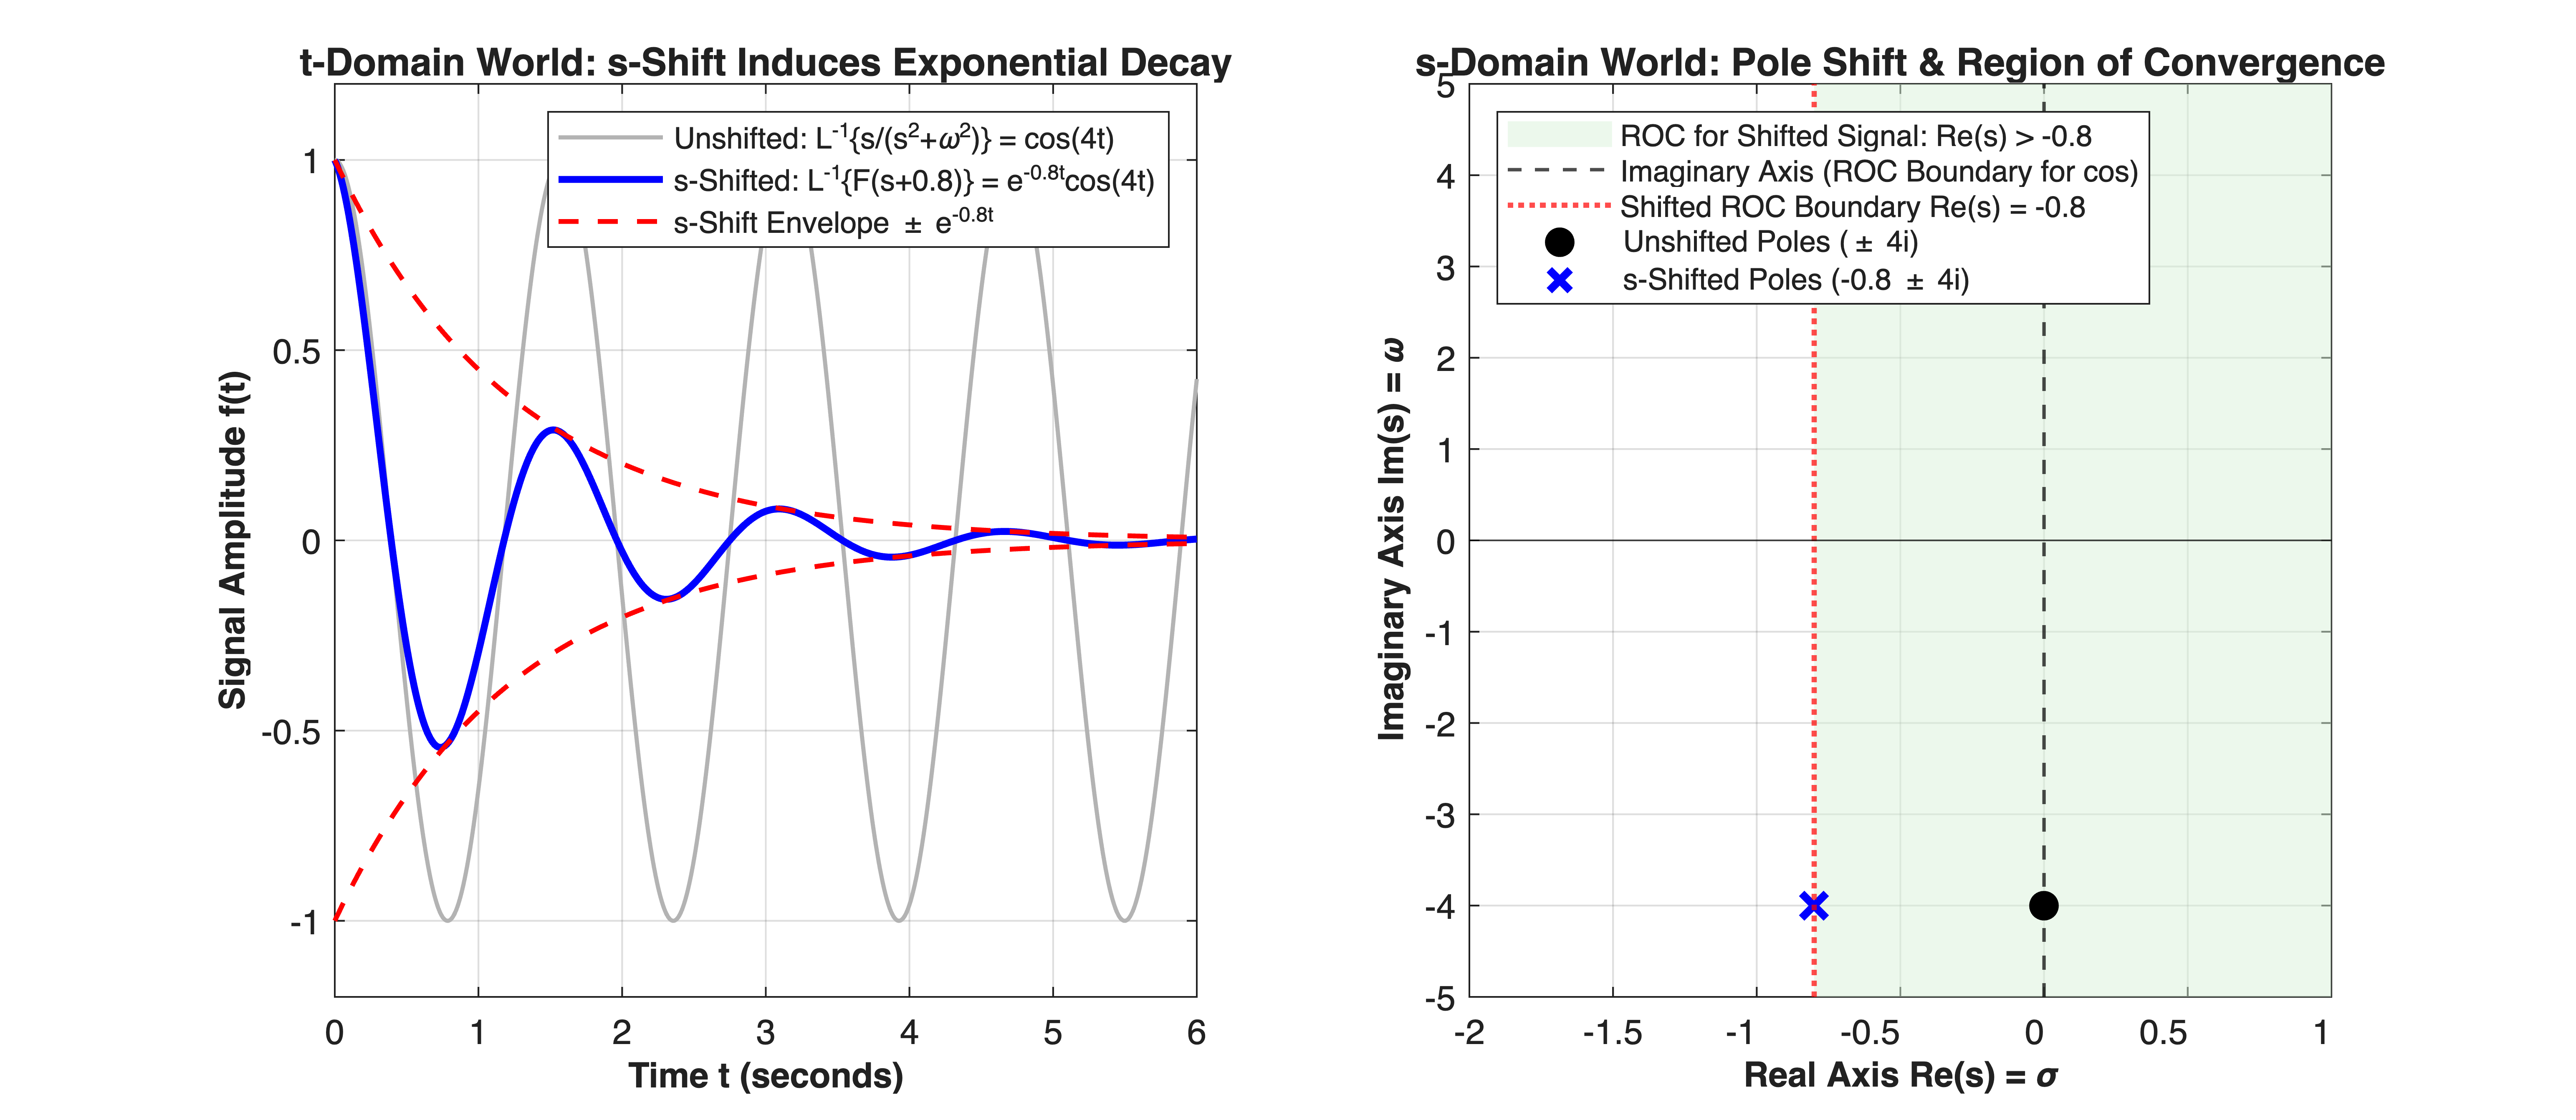

In [5]:


% Time-domain recovery using Control System Toolbox 'impulse'
% Because Y(s) = F(s)*U(s) and U(s) = L[delta(t)] = 1, impulse(F) yields L^-1{F(s)}!
t_eval = linspace(0, 6.0, 1000);
[f1_time, ~] = impulse(F_cos_unshifted, t_eval);
[f2_time, ~] = impulse(F_cos_shifted,   t_eval);


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 500]);


% Subplot 1: t-Domain Signals & Exponential Envelope
subplot(1, 2, 1);
hold on; grid on; box on;


plot(t_eval, f1_time, 'Color', [0.7 0.7 0.7], 'LineWidth', 1.2, ...
    'DisplayName', 'Unshifted: L^{-1}\{s/(s^2+\omega^2)\} = cos(4t)');
plot(t_eval, f2_time, 'b-', 'LineWidth', 2.0, ...
    'DisplayName', 's-Shifted: L^{-1}\{F(s+0.8)\} = e^{-0.8t}cos(4t)');
plot(t_eval, exp(a_shift * t_eval), 'r--', 'LineWidth', 1.4, ...
    'DisplayName', 's-Shift Envelope \pm e^{-0.8t}');
plot(t_eval, -exp(a_shift * t_eval), 'r--', 'LineWidth', 1.4, 'HandleVisibility', 'off');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Signal Amplitude f(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('t-Domain World: s-Shift Induces Exponential Decay', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([0, 6.0]);
ylim([-1.2, 1.2]);


% Subplot 2: s-Domain Pole-Zero Map & Region of Convergence (ROC)
subplot(1, 2, 2);
hold on; grid on; box on;


% Shade ROC for shifted signal: Re(s) > -0.8
x_patch = [a_shift, 1.5, 1.5, a_shift];
y_patch = [-5, -5, 5, 5];
patch(x_patch, y_patch, [0.85 0.95 0.85], 'EdgeColor', 'none', ...
    'FaceAlpha', 0.5, 'DisplayName', 'ROC for Shifted Signal: Re(s) > -0.8');


xline(0, 'k--', 'LineWidth', 1.0, 'DisplayName', 'Imaginary Axis (ROC Boundary for cos)');
xline(a_shift, 'r:', 'LineWidth', 1.5, 'DisplayName', 'Shifted ROC Boundary Re(s) = -0.8');
yline(0, 'k-', 'LineWidth', 0.5, 'HandleVisibility', 'off');


plot(real(poles_unshifted), imag(poles_unshifted), 'ko', 'MarkerFaceColor', 'k', ...
    'MarkerSize', 8, 'DisplayName', 'Unshifted Poles (\pm 4i)');
plot(real(poles_shifted), imag(poles_shifted), 'bx', 'LineWidth', 2.2, ...
    'MarkerSize', 10, 'DisplayName', 's-Shifted Poles (-0.8 \pm 4i)');


xlabel('Real Axis Re(s) = \sigma', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Imaginary Axis Im(s) = \omega', 'FontSize', 10, 'FontWeight', 'bold');
title('s-Domain World: Pole Shift & Region of Convergence', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);
xlim([-2.0, 1.0]);
ylim([-5.0, 5.0]);